In [1]:
!pip install lightgbm
!pip install catboost


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install lightgbm imbalanced-learn -q


[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, roc_curve,
    classification_report, f1_score,
    matthews_corrcoef, fbeta_score
)

# SMOTE
from imblearn.over_sampling import SMOTE

# Classifiers
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.neural_network import MLPClassifier

# AutoEncoder
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

print('✅ Semua library berhasil diimport.')

✅ Semua library berhasil diimport.


In [4]:
df = pd.read_csv('creditcard1.csv')
print(f"Shape dataset: {df.shape}")
df.head()

Shape dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Legitimate (0) : 284315 (99.827%)
Fraudulent (1) : 492 (0.173%)


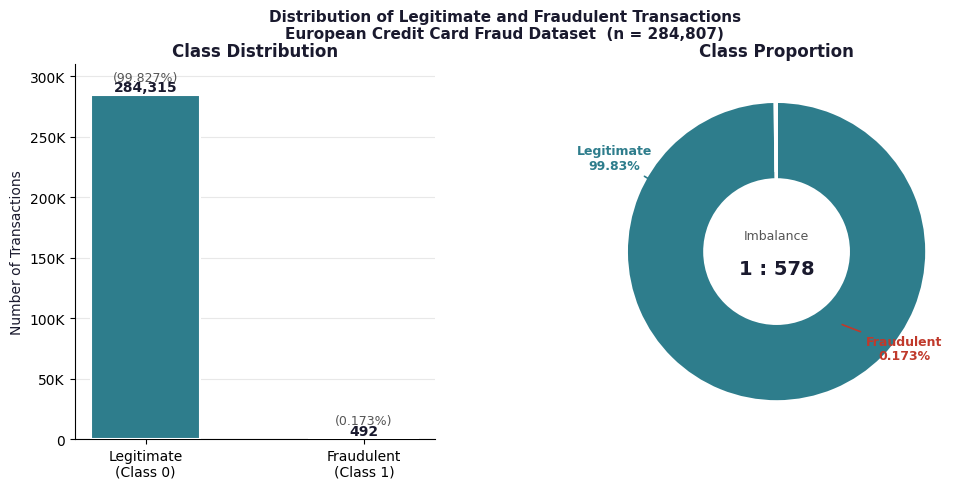

In [5]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ── Data ──────────────────────────────────────────────────────────────
class_counts = df['Class'].value_counts()
n_legitimate = class_counts[0]
n_fraud      = class_counts[1]
total        = len(df)
pct_legit    = n_legitimate / total * 100
pct_fraud    = n_fraud      / total * 100

print(f"Legitimate (0) : {n_legitimate} ({pct_legit:.3f}%)")
print(f"Fraudulent (1) : {n_fraud} ({pct_fraud:.3f}%)")

# ── Color palette ──────────────────────────────────────────────────────
COL_LEGIT = '#2E7D8C'
COL_FRAUD = '#C0392B'
COL_BG    = '#FFFFFF'
COL_GRID  = '#E8E8E8'
COL_TEXT  = '#1A1A2E'
COL_SUB   = '#555555'

fig = plt.figure(figsize=(10, 5), facecolor=COL_BG)
fig.subplots_adjust(left=0.07, right=0.97, top=0.88, bottom=0.13, wspace=0.38)
gs  = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1, 1.1])

# Panel kiri — Bar chart
ax1 = fig.add_subplot(gs[0])
ax1.set_facecolor(COL_BG)
bars = ax1.bar(['Legitimate\n(Class 0)', 'Fraudulent\n(Class 1)'],
               [n_legitimate, n_fraud],
               color=[COL_LEGIT, COL_FRAUD],
               width=0.5, edgecolor='white', linewidth=1.5, zorder=3)
ax1.yaxis.grid(True, color=COL_GRID, linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
for bar, val, pct in zip(bars, [n_legitimate, n_fraud], [pct_legit, pct_fraud]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3000,
             f'{val:,}', ha='center', fontsize=10, fontweight='bold', color=COL_TEXT)
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 12000,
             f'({pct:.3f}%)', ha='center', fontsize=9, color=COL_SUB)
ax1.set_ylabel('Number of Transactions', fontsize=10, color=COL_TEXT)
ax1.set_ylim(0, 310000)
ax1.set_title('Class Distribution', fontsize=12, fontweight='bold', color=COL_TEXT)
ax1.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{int(x/1000)}K' if x >= 1000 else str(int(x))))
for spine in ['top', 'right']:
    ax1.spines[spine].set_visible(False)

# Panel kanan — Donut chart
ax2 = fig.add_subplot(gs[1])
ax2.set_facecolor(COL_BG)
ax2.pie([pct_legit, pct_fraud],
        colors=[COL_LEGIT, COL_FRAUD],
        explode=(0, 0.06), startangle=90,
        wedgeprops=dict(width=0.52, edgecolor='white', linewidth=2),
        counterclock=False)
ax2.text(0,  0.08, 'Imbalance', ha='center', fontsize=9,  color=COL_SUB)
ax2.text(0, -0.15, '1 : 578',   ha='center', fontsize=14, fontweight='bold', color=COL_TEXT)
ax2.annotate(f'Legitimate\n{pct_legit:.2f}%',
             xy=(-0.55, 0.30), xytext=(-1.08, 0.55), ha='center',
             fontsize=9, color=COL_LEGIT, fontweight='bold',
             arrowprops=dict(arrowstyle='-', color=COL_LEGIT, lw=1.2))
ax2.annotate(f'Fraudulent\n{pct_fraud:.3f}%',
             xy=(0.42, -0.48), xytext=(0.85, -0.72), ha='center',
             fontsize=9, color=COL_FRAUD, fontweight='bold',
             arrowprops=dict(arrowstyle='-', color=COL_FRAUD, lw=1.2))
ax2.set_title('Class Proportion', fontsize=12, fontweight='bold', color=COL_TEXT)

fig.suptitle(
    'Distribution of Legitimate and Fraudulent Transactions\n'
    'European Credit Card Fraud Dataset  (n = 284,807)',
    fontsize=11, fontweight='bold', color=COL_TEXT, y=0.99)

plt.savefig('class_distribution.png', dpi=300, bbox_inches='tight', facecolor=COL_BG)
plt.show()

In [6]:
# Handle missing values
if df.isnull().sum().max() > 0:
    df = df.fillna(df.mean())
    print("Missing values diisi dengan mean.")
else:
    print("Tidak ada missing values.")

X = df.drop(['Class', 'Time'], axis=1).values
y = df['Class'].values

print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")

Tidak ada missing values.
Shape X : (284807, 29)
Shape y : (284807,)


SPLIT

In [7]:
from sklearn.model_selection import train_test_split

X_train_full, X_test_final, y_train_full, y_test_final = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Train Set:", X_train_full.shape)
print("Test Set :", X_test_final.shape)
print(f"Fraud -> Train: {sum(y_train_full)} | Test: {sum(y_test_final)}")


Train Set: (227845, 29)
Test Set : (56962, 29)
Fraud -> Train: 394 | Test: 98


In [ ]:
LATENT_DIM = 256   # dimensi latent space AutoEncoder

def build_autoencoder(input_dim):
    """AutoEncoder — sama untuk semua model & semua fold."""
    inp     = Input(shape=(input_dim,))
    enc     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(inp)
    latent  = Dense(LATENT_DIM, activation='relu', kernel_regularizer=l2(0.001))(enc)
    dec     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(latent)
    out     = Dense(input_dim, activation='linear')(dec)

    ae      = Model(inputs=inp, outputs=out)
    encoder = Model(inputs=inp, outputs=latent)
    # mse lebih tepat dari binary_crossentropy untuk data StandardScaler
    # (nilainya kontinu & bisa negatif, bukan probabilitas 0-1)
    ae.compile(optimizer=Adam(learning_rate=0.0001), loss='mse')
    return ae, encoder


def extract_hybrid_features(ae, encoder, X_tr, X_te):
    """Gabung: Original Features + Latent Space + MSE Reconstruction Error."""
    mse_tr  = np.mean(np.power(X_tr - ae.predict(X_tr, verbose=0), 2), axis=1, keepdims=True)
    mse_te  = np.mean(np.power(X_te - ae.predict(X_te, verbose=0), 2), axis=1, keepdims=True)
    lat_tr  = encoder.predict(X_tr, verbose=0)
    lat_te  = encoder.predict(X_te, verbose=0)
    return np.hstack((X_tr, lat_tr, mse_tr)), np.hstack((X_te, lat_te, mse_te))


SMOTE_SAMPLING_STRATEGY = 0.10  # rasio minoritas:majoritas setelah resampling
                                 # 0.10 -> fraud:normal jadi ~10:90 (bukan 50:50 penuh)

def apply_smote(X_hybrid_train, y_train, fold_num, sampling_strategy=SMOTE_SAMPLING_STRATEGY):
    """
    SMOTE diterapkan HANYA pada X_train_hybrid (Pilihan B).
    X_test tidak disentuh — tetap distribusi asli.

    sampling_strategy : rasio jumlah sampel minoritas (fraud) dibagi
    majoritas (normal) SETELAH resampling. 1.0 = balance penuh 50:50.
    0.10 = fraud dibuat jadi 10% dari normal (rasio ~80:20), supaya model
    tidak terlalu "berani" menandai fraud (mengurangi false positive).
    """
    sm = SMOTE(random_state=42, k_neighbors=5, sampling_strategy=sampling_strategy)
    X_res, y_res = sm.fit_resample(X_hybrid_train, y_train)
    fraud_before  = int(np.sum(y_train == 1))
    fraud_after   = int(np.sum(y_res == 1))
    normal_after  = int(np.sum(y_res == 0))
    print(f'[Fold {fold_num}] SMOTE (sampling_strategy={sampling_strategy}): '
          f'fraud {fraud_before} → {fraud_after} | normal tetap {normal_after} | '
          f'total train {len(y_train)} → {len(y_res)}')
    return X_res, y_res


RECALL_WEIGHT = 0.80
def find_optimal_threshold(model, X_val, y_val, weight=RECALL_WEIGHT):
    prob = model.predict_proba(X_val)[:,1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)

    j_scores = (weight * tpr) - ((1 - weight) * fpr)
    best_t = thresholds[np.argmax(j_scores)]

    return best_t


SOTA_ACC    = 0.95130
SOTA_RECALL = 0.91176
WEIGHT_CANDIDATES = [0.60, 0.65, 0.70, 0.75, 0.80]

def find_thresholds_multi_weight(model, X_val, y_val, weights=WEIGHT_CANDIDATES):
    """
    Hitung threshold Youden's J untuk BEBERAPA weight sekaligus, dari
    SATU kali predict_proba + SATU kali roc_curve saja (efisien, model
    tidak perlu di-retrain per weight).
    Return: dict {weight: threshold}
    """
    prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)
    out = {}
    for w in weights:
        j = (w * tpr) - ((1 - w) * fpr)
        out[w] = thresholds[np.argmax(j)]
    return out


print('Fungsi helper siap.')


Fungsi helper siap.


SPLIT DATA 80/20

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

MODEL_NAMES = ['AE + XGBoost', 'AE + Random Forest', 'AE + CatBoost', 'AE + LightGBM', 'AE + MLP']

# results[model][weight] = {'acc':[], 'dr':[]}  -- nested per kandidat weight
# auc_results[model] = []  -- AUC tidak tergantung threshold/weight, jadi flat saja
results = {m: {w: {'acc': [], 'dr': [], 'f1': []} for w in WEIGHT_CANDIDATES} for m in MODEL_NAMES}
auc_results = {m: [] for m in MODEL_NAMES}

# fold_thresholds[model][weight] = [list threshold per fold]
fold_thresholds = {m: {w: [] for w in WEIGHT_CANDIDATES} for m in MODEL_NAMES}

last_fold = {}

for fold_num, (train_idx, val_idx) in enumerate(
    skf.split(X_train_full, y_train_full),
    start=1
):
    print(f'\n{"="*55}')
    print(f'                   FOLD {fold_num} / 5')
    print(f'{"="*55}')

    X_train_raw = X_train_full[train_idx]
    X_val_raw   = X_train_full[val_idx]

    y_train = y_train_full[train_idx]
    y_val   = y_train_full[val_idx]

    # ── Scaling ──────────────────────────────────────────────
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_val   = scaler.transform(X_val_raw)

    print(f'Train: {X_train.shape} | Validation: {X_val.shape}')
    print(f'Fraud di train: {sum(y_train)} | Fraud di validation: {sum(y_val)}')

    # ── AutoEncoder ───────────────────────────────────────────
    X_train_normal = X_train[y_train == 0]
    ae, encoder = build_autoencoder(X_train.shape[1])
    ae.fit(
        X_train_normal, X_train_normal,
        epochs=50, batch_size=64, validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    print(f'[Fold {fold_num}] AutoEncoder selesai (training dari data normal saja).')

    # ── Ekstraksi Fitur Hybrid ────────────────────────────────
    X_train_hybrid, X_val_hybrid = extract_hybrid_features(
        ae, encoder, X_train, X_val
    )
    print(f'[Fold {fold_num}] Dimensi hybrid: {X_train_hybrid.shape[1]} fitur')

    # ── Split internal: Fit (training model) vs Threshold-tuning ──
    X_fit_hybrid, X_thresh_hybrid, y_fit, y_thresh = train_test_split(
        X_train_hybrid, y_train,
        test_size=0.2, stratify=y_train, random_state=42
    )
    print(f'[Fold {fold_num}] Split internal -> Fit: {X_fit_hybrid.shape[0]} | '
          f'Threshold-tuning: {X_thresh_hybrid.shape[0]} | Val (evaluasi): {X_val_hybrid.shape[0]}')

    # ── SMOTE ─────────────────────────────────────
    X_tr, y_tr = apply_smote(
        X_fit_hybrid,
        y_fit,
        fold_num
    )

    models_this_fold = {}

    # ════════════════════════════════════════
    # MODEL 1 — AE + XGBoost
    # ════════════════════════════════════════
    m1 = xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=6,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        random_state=42, eval_metric='auc', verbosity=0
    )
    m1.fit(X_tr, y_tr)
    models_this_fold['AE + XGBoost'] = m1

    # ════════════════════════════════════════
    # MODEL 2 — AE + Random Forest
    # ════════════════════════════════════════
    m2 = RandomForestClassifier(
        n_estimators=200, max_depth=None,
        n_jobs=-1, random_state=42
    )
    m2.fit(X_tr, y_tr)
    models_this_fold['AE + Random Forest'] = m2

    # ════════════════════════════════════════
    # MODEL 3 — AE + Catboost
    # ════════════════════════════════════════
    m3 = CatBoostClassifier(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        random_state=42,
        verbose=0
    )
    m3.fit(X_tr, y_tr)
    models_this_fold['AE + CatBoost'] = m3

    # ════════════════════════════════════════
    # MODEL 4 — AE + LightGBM
    # ════════════════════════════════════════
    m4 = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=6, subsample=0.8, colsample_bytree=0.8,
        is_unbalance=False,
        random_state=42, verbose=-1
    )
    m4.fit(X_tr, y_tr)
    models_this_fold['AE + LightGBM'] = m4

    # ════════════════════════════════════════
    # MODEL 5 — AE + MLP
    # ════════════════════════════════════════
    m5 = MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation='relu', solver='adam',
        learning_rate_init=0.001, max_iter=200,
        early_stopping=True, validation_fraction=0.1,
        random_state=42
    )
    m5.fit(X_tr, y_tr)
    models_this_fold['AE + MLP'] = m5

    # ── Untuk tiap model: hitung threshold di SEMUA weight kandidat,
    #    lalu evaluasi tiap weight ke val fold ini (tanpa retrain) ──
    fold_preds_for_last = {}
    for name, model in models_this_fold.items():
        thresh_dict = find_thresholds_multi_weight(model, X_thresh_hybrid, y_thresh, WEIGHT_CANDIDATES)
        prob_val = model.predict_proba(X_val_hybrid)[:, 1]
        auc_results[name].append(roc_auc_score(y_val, prob_val) * 100)

        for w in WEIGHT_CANDIDATES:
            t = thresh_dict[w]
            pred = (prob_val >= t).astype(int)
            results[name][w]['acc'].append(accuracy_score(y_val, pred) * 100)
            results[name][w]['dr'].append(recall_score(y_val, pred, zero_division=0) * 100)
            results[name][w]['f1'].append(f1_score(y_val, pred, zero_division=0) * 100)
            fold_thresholds[name][w].append(t)

        # simpan prediksi pakai weight default (0.80) hanya buat referensi last_fold
        default_t = thresh_dict[RECALL_WEIGHT]
        fold_preds_for_last[name] = (y_val, (prob_val >= default_t).astype(int), prob_val)

        print(f'[Fold {fold_num}] {name:<20} AUC:{auc_results[name][-1]:.2f}% | '
              + ' | '.join(f'w={w}: Acc={results[name][w]["acc"][-1]:.1f}/DR={results[name][w]["dr"][-1]:.1f}'
                           for w in WEIGHT_CANDIDATES))

    if fold_num == 5:
        last_fold = fold_preds_for_last

print('\n' + '='*55)
print('Training & evaluasi selesai untuk semua fold.')
print('='*55)



                   FOLD 1 / 5
Train: (182276, 29) | Validation: (45569, 29)
Fraud di train: 316 | Fraud di validation: 78
[Fold 1] AutoEncoder selesai (training dari data normal saja).
[Fold 1] Dimensi hybrid: 286 fitur
[Fold 1] Split internal -> Fit: 145820 | Threshold-tuning: 36456 | Val (evaluasi): 45569
[Fold 1] SMOTE (sampling_strategy=0.1): fraud 253 → 14556 | normal tetap 145567 | total train 145820 → 160123
[Fold 1] AE + XGBoost         AUC:99.37% | w=0.6: Acc=91.7/DR=97.4 | w=0.65: Acc=91.7/DR=97.4 | w=0.7: Acc=91.7/DR=97.4 | w=0.75: Acc=82.4/DR=98.7 | w=0.8: Acc=82.4/DR=98.7
[Fold 1] AE + Random Forest   AUC:98.95% | w=0.6: Acc=96.6/DR=96.2 | w=0.65: Acc=96.6/DR=96.2 | w=0.7: Acc=93.5/DR=96.2 | w=0.75: Acc=93.5/DR=96.2 | w=0.8: Acc=93.5/DR=96.2
[Fold 1] AE + CatBoost        AUC:99.13% | w=0.6: Acc=96.6/DR=96.2 | w=0.65: Acc=96.6/DR=96.2 | w=0.7: Acc=86.0/DR=98.7 | w=0.75: Acc=86.0/DR=98.7 | w=0.8: Acc=86.0/DR=98.7
[Fold 1] AE + LightGBM        AUC:98.99% | w=0.6: Acc=93.3/DR

In [10]:
print("\n" + "="*70)
print("PERBANDINGAN WEIGHT (rata-rata 5-fold CV) -- dari data TRAIN saja")
print("="*70)

best_weight_per_model = {}

for name in MODEL_NAMES:
    print(f"\n{name}  (AUC rata-rata: {np.mean(auc_results[name]):.2f}%)")
    print(f"{'Weight':<10}{'Acc (CV avg)':<16}{'Recall (CV avg)':<18}{'F1 (CV avg)':<14}")

    for w in WEIGHT_CANDIDATES:
        acc = np.mean(results[name][w]['acc'])
        dr  = np.mean(results[name][w]['dr'])
        f1  = np.mean(results[name][w]['f1'])
        flag = '(vs SOTA: *)' if (acc/100 >= SOTA_ACC and dr/100 >= SOTA_RECALL) else ''
        print(f"{w:<10}{acc:<16.2f}{dr:<18.2f}{f1:<14.2f}{flag}")

    # Kriteria pemilihan: F1-score CV rata-rata TERTINGGI -- metrik yang
    # berdiri sendiri (tidak menyebut/mengacu ke angka SOTA sama sekali),
    # supaya pemilihan weight tidak "diarahkan" untuk mengalahkan SOTA.
    best_w = max(WEIGHT_CANDIDATES, key=lambda w: np.mean(results[name][w]['f1']))
    best_weight_per_model[name] = best_w
    print(f"--> Weight terpilih untuk {name}: {best_w}  "
          f"(berdasarkan F1-score CV tertinggi: {np.mean(results[name][best_w]['f1']):.2f}%)")

print(f"\n('(vs SOTA: *)' di atas cuma INFORMASI tambahan -- BUKAN kriteria "
      f"pemilihan. Weight dipilih murni berdasarkan F1-score CV tertinggi.)")
print(f"\nWeight terpilih per model: {best_weight_per_model}")



PERBANDINGAN WEIGHT (rata-rata 5-fold CV) -- dari data TRAIN saja

AE + XGBoost  (AUC rata-rata: 98.35%)
Weight    Acc (CV avg)    Recall (CV avg)   F1 (CV avg)   
0.6       93.78           92.40             8.79          
0.65      93.16           93.16             7.30          
0.7       92.52           93.41             6.88          
0.75      90.66           93.67             6.48          
0.8       90.66           93.67             6.48          
--> Weight terpilih untuk AE + XGBoost: 0.6  (berdasarkan F1-score CV tertinggi: 8.79%)

AE + Random Forest  (AUC rata-rata: 97.92%)
Weight    Acc (CV avg)    Recall (CV avg)   F1 (CV avg)   
0.6       98.09           91.64             17.05         (vs SOTA: *)
0.65      98.09           91.64             17.05         (vs SOTA: *)
0.7       97.47           91.64             16.25         (vs SOTA: *)
0.75      95.85           92.90             12.29         (vs SOTA: *)
0.8       94.77           93.91             7.11          
--> W

In [11]:
# best_thresholds = rata-rata threshold dari 5 fold, MASING-MASING DIAMBIL
# DARI WEIGHT YANG SUDAH TERPILIH (paling seimbang) untuk model itu --
# bukan dari satu weight global yang sama untuk semua model.
best_thresholds = {
    name: np.mean(fold_thresholds[name][best_weight_per_model[name]])
    for name in MODEL_NAMES
}

print("Threshold rata-rata (dari 5 fold, sesuai weight terpilih tiap model):")
for name in MODEL_NAMES:
    w = best_weight_per_model[name]
    per_fold = ", ".join(f"{x:.3f}" for x in fold_thresholds[name][w])
    print(f"  {name:<20} (weight={w}): {best_thresholds[name]:.4f}   (per-fold: {per_fold})")


Threshold rata-rata (dari 5 fold, sesuai weight terpilih tiap model):
  AE + XGBoost         (weight=0.6): 0.0045   (per-fold: 0.002, 0.005, 0.014, 0.001, 0.001)
  AE + Random Forest   (weight=0.6): 0.0410   (per-fold: 0.025, 0.040, 0.070, 0.035, 0.035)
  AE + CatBoost        (weight=0.6): 0.0145   (per-fold: 0.015, 0.007, 0.011, 0.028, 0.012)
  AE + LightGBM        (weight=0.6): 0.0032   (per-fold: 0.002, 0.003, 0.008, 0.003, 0.001)
  AE + MLP             (weight=0.6): 0.0000   (per-fold: 0.000, 0.000, 0.000, 0.000, 0.000)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_full)
X_test_scaled  = scaler.transform(X_test_final)


In [13]:
X_train_normal = X_train_scaled[y_train_full == 0]

ae, encoder = build_autoencoder(X_train_scaled.shape[1])

ae.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 18s 5ms/step - loss: 0.4300 - val_loss: 0.1822
Epoch 2/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.1307 - val_loss: 0.0924
Epoch 3/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.0805 - val_loss: 0.0687
Epoch 4/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.0646 - val_loss: 0.0593
Epoch 5/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.0582 - val_loss: 0.0540
Epoch 6/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.0543 - val_loss: 0.0511
Epoch 7/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.0507 - val_loss: 0.0481
Epoch 8/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 0.0482 - val_loss: 0.0524
Epoch 9/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.0463 - val_loss: 0.0449
Epoch 10/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - loss: 0.0447 - val_loss: 0.0462
Epoch 11/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - loss: 0.0439 - val_loss: 0.0415
Epoch 12/50
3199/31

In [14]:
X_train_hybrid, X_test_hybrid = extract_hybrid_features(
    ae,
    encoder,
    X_train_scaled,
    X_test_scaled
)


In [15]:
X_train_smote, y_train_smote = apply_smote(
    X_train_hybrid,
    y_train_full,
    fold_num=0
)

[Fold 0] SMOTE (sampling_strategy=0.1): fraud 394 → 22745 | normal tetap 227451 | total train 227845 → 250196


In [16]:
m1 = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    verbosity=0
)
m1.fit(X_train_smote, y_train_smote)

m2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    random_state=42
)
m2.fit(X_train_smote, y_train_smote)

m3 = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    random_state=42,
    verbose=0
)
m3.fit(X_train_smote, y_train_smote)

m4 = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    is_unbalance=False,
    random_state=42,
    verbose=-1
)
m4.fit(X_train_smote, y_train_smote)

m5 = MLPClassifier(
    hidden_layer_sizes=(256,128,64),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
m5.fit(X_train_smote, y_train_smote)

,hidden_layer_sizes,"(256, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,42


In [17]:
final_models = {
    "AE + XGBoost": m1,
    "AE + Random Forest": m2,
    "AE + CatBoost": m3,
    "AE + LightGBM": m4,
    "AE + MLP": m5
}

In [18]:
from sklearn.metrics import classification_report

all_predictions = {}

print("\nFINAL HOLD-OUT TEST RESULTS")
print("="*60)

for name, model in final_models.items():

    prob = model.predict_proba(X_test_hybrid)[:,1]

    threshold = best_thresholds[name]   # rata-rata threshold dari 5 fold CV

    pred = (prob >= threshold).astype(int)

    # simpan hasil prediksi (dict, dipakai cell confusion matrix/ROC/PR di bawah)
    all_predictions[name] = {'pred': pred, 'prob': prob}

    acc = accuracy_score(y_test_final, pred)*100
    dr  = recall_score(y_test_final, pred)*100
    auc = roc_auc_score(y_test_final, prob)*100

    print(
        f"{name:<20}"
        f" Acc={acc:.2f}%"
        f" | DR={dr:.2f}%"
        f" | AUC={auc:.2f}%"
    )



FINAL HOLD-OUT TEST RESULTS
AE + XGBoost         Acc=95.37% | DR=92.86% | AUC=97.95%
AE + Random Forest   Acc=98.67% | DR=90.82% | AUC=97.94%
AE + CatBoost        Acc=95.56% | DR=94.90% | AUC=98.47%
AE + LightGBM        Acc=94.58% | DR=93.88% | AUC=97.97%
AE + MLP             Acc=95.77% | DR=89.80% | AUC=97.24%


In [19]:
# ── Bootstrap 95% Confidence Interval ──────────────────────────────
# Resampling Test set (DENGAN pengembalian) sebanyak N_BOOTSTRAP kali,
# lalu hitung ulang Acc/DR/AUC dari prediksi yang SUDAH ADA (tanpa
# retrain apapun). Ini menunjukkan seberapa STABIL angka hasil test kita
# -- bukan cuma satu titik angka, tapi rentang yang masuk akal.
#
# PENTING: ini cuma analisis statistik tambahan untuk laporan, BUKAN
# dipakai untuk memilih threshold/weight apapun -- jadi tidak melanggar
# aturan anti-leakage yang sudah kita pegang sejak awal.

N_BOOTSTRAP = 1000
rng = np.random.RandomState(42)
n_test = len(y_test_final)

bootstrap_results = {name: {'acc': [], 'dr': [], 'auc': []} for name in all_predictions}

for name, data in all_predictions.items():
    pred = data['pred']
    prob = data['prob']

    for _ in range(N_BOOTSTRAP):
        idx = rng.randint(0, n_test, n_test)   # resample dengan pengembalian
        y_bs    = y_test_final[idx]
        pred_bs = pred[idx]
        prob_bs = prob[idx]

        if len(np.unique(y_bs)) < 2:
            continue   # skip kalau kebetulan resample tidak punya 2 kelas (jarang terjadi)

        bootstrap_results[name]['acc'].append(accuracy_score(y_bs, pred_bs) * 100)
        bootstrap_results[name]['dr'].append(recall_score(y_bs, pred_bs, zero_division=0) * 100)
        bootstrap_results[name]['auc'].append(roc_auc_score(y_bs, prob_bs) * 100)

print(f"BOOTSTRAP 95% CONFIDENCE INTERVAL  (n={N_BOOTSTRAP} resample dari Test set)")
print("="*78)

ci_summary = {}
for name in all_predictions:
    acc_arr = np.array(bootstrap_results[name]['acc'])
    dr_arr  = np.array(bootstrap_results[name]['dr'])
    auc_arr = np.array(bootstrap_results[name]['auc'])

    acc_ci = np.percentile(acc_arr, [2.5, 97.5])
    dr_ci  = np.percentile(dr_arr,  [2.5, 97.5])
    auc_ci = np.percentile(auc_arr, [2.5, 97.5])
    ci_summary[name] = {'acc': (acc_arr.mean(), acc_ci), 'dr': (dr_arr.mean(), dr_ci), 'auc': (auc_arr.mean(), auc_ci)}

    # cek apakah BATAS BAWAH CI masih melebihi SOTA -> klaim "menang" jadi kuat secara statistik
    acc_beats_sota_robustly = acc_ci[0] >= SOTA_ACC * 100
    dr_beats_sota_robustly  = dr_ci[0]  >= SOTA_RECALL * 100

    print(f"\n{name}")
    print(f"  Acc: {acc_arr.mean():6.2f}%   95% CI: [{acc_ci[0]:6.2f}% , {acc_ci[1]:6.2f}%]"
          f"   {'(robust > SOTA)' if acc_beats_sota_robustly else ''}")
    print(f"  DR : {dr_arr.mean():6.2f}%   95% CI: [{dr_ci[0]:6.2f}% , {dr_ci[1]:6.2f}%]"
          f"   {'(robust > SOTA)' if dr_beats_sota_robustly else ''}")
    print(f"  AUC: {auc_arr.mean():6.2f}%   95% CI: [{auc_ci[0]:6.2f}% , {auc_ci[1]:6.2f}%]")

print(f"\n('robust > SOTA' artinya BATAS BAWAH dari 95% CI masih di atas angka SOTA"
      f" -- jadi unggulnya bukan kebetulan dari satu sampel test, tapi konsisten secara statistik.)")


BOOTSTRAP 95% CONFIDENCE INTERVAL  (n=1000 resample dari Test set)

AE + XGBoost
  Acc:  95.37%   95% CI: [ 95.19% ,  95.54%]   (robust > SOTA)
  DR :  92.98%   95% CI: [ 87.95% ,  97.53%]   
  AUC:  98.00%   95% CI: [ 95.93% ,  99.51%]

AE + Random Forest
  Acc:  98.67%   95% CI: [ 98.57% ,  98.76%]   (robust > SOTA)
  DR :  90.94%   95% CI: [ 85.00% ,  96.20%]   
  AUC:  97.96%   95% CI: [ 95.66% ,  99.80%]

AE + CatBoost
  Acc:  95.56%   95% CI: [ 95.39% ,  95.72%]   (robust > SOTA)
  DR :  94.81%   95% CI: [ 90.11% ,  98.89%]   
  AUC:  98.43%   95% CI: [ 96.93% ,  99.61%]

AE + LightGBM
  Acc:  94.57%   95% CI: [ 94.39% ,  94.76%]   
  DR :  93.89%   95% CI: [ 88.89% ,  98.13%]   
  AUC:  97.96%   95% CI: [ 95.80% ,  99.70%]

AE + MLP
  Acc:  95.76%   95% CI: [ 95.60% ,  95.94%]   (robust > SOTA)
  DR :  89.80%   95% CI: [ 83.17% ,  95.33%]   
  AUC:  97.25%   95% CI: [ 94.94% ,  99.08%]

('robust > SOTA' artinya BATAS BAWAH dari 95% CI masih di atas angka SOTA -- jadi unggulnya b

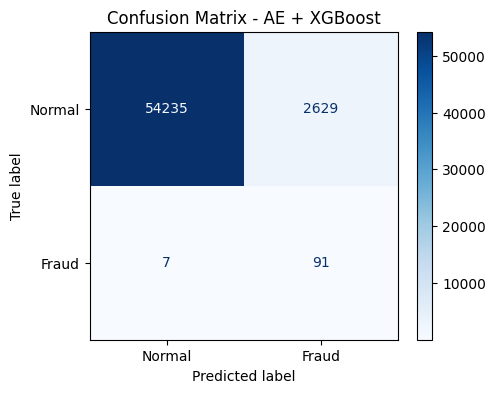

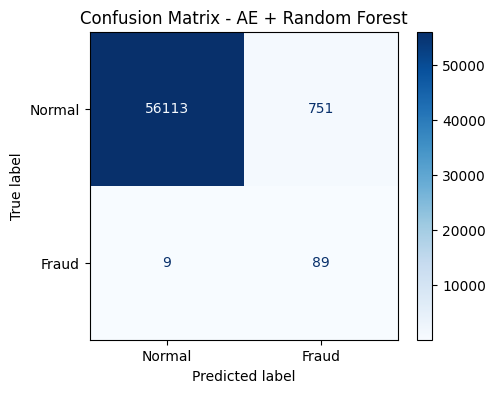

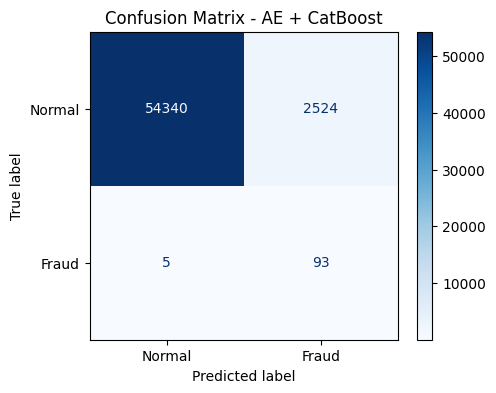

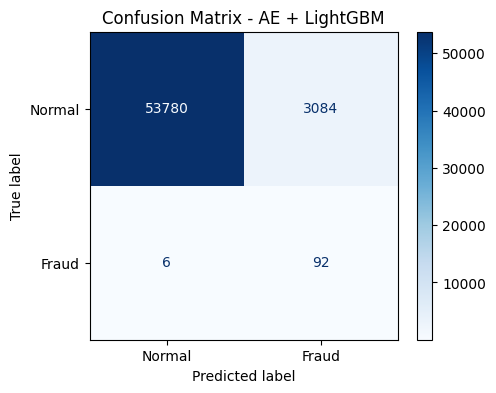

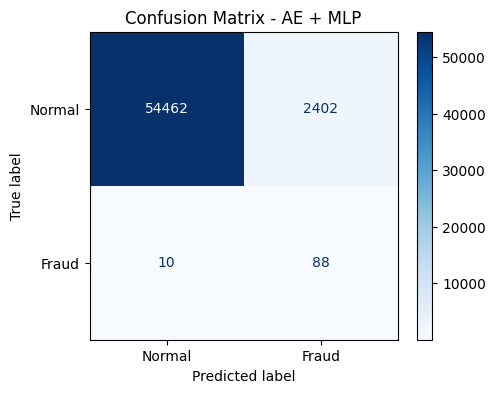

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, data in all_predictions.items():

    pred = data['pred']

    cm = confusion_matrix(y_test_final, pred)

    fig, ax = plt.subplots(figsize=(5,4))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Normal','Fraud']
    )

    disp.plot(ax=ax, cmap='Blues')

    plt.title(f'Confusion Matrix - {name}')
    plt.show()

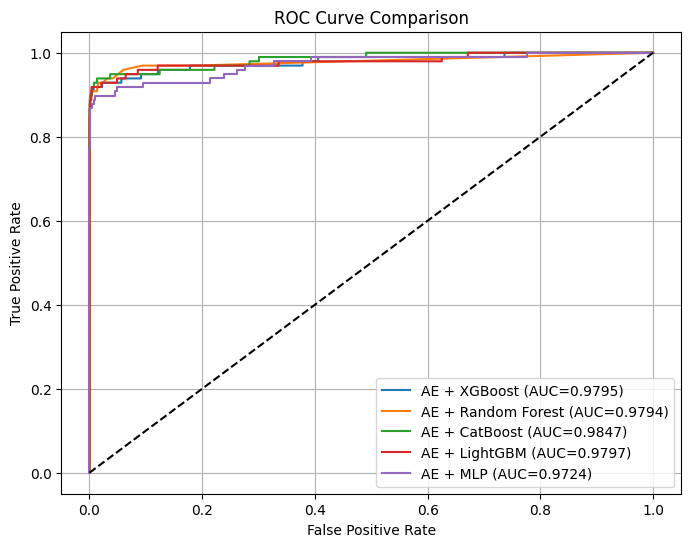

In [21]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    fpr, tpr, _ = roc_curve(y_test_final, prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC={roc_auc:.4f})'
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)

plt.show()

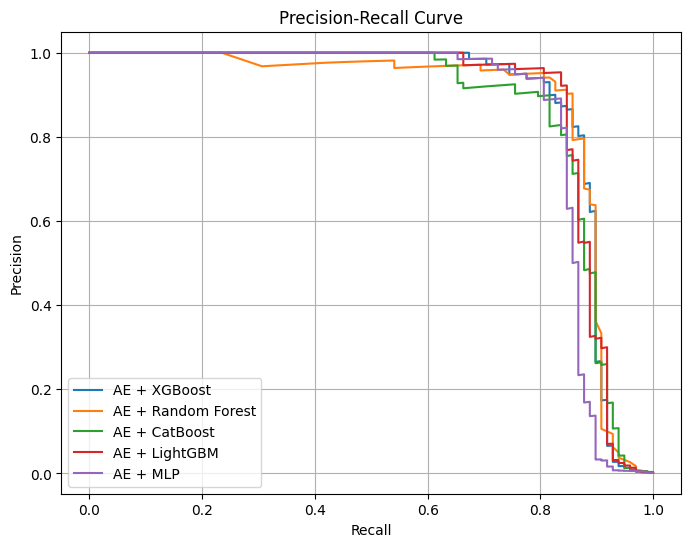

In [22]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    precision, recall, _ = precision_recall_curve(
        y_test_final,
        prob
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)

plt.show()

In [23]:
for name, data in all_predictions.items():

    pred = data['pred']

    print("\n" + "="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test_final,
            pred,
            digits=4
        )
    )



AE + XGBoost
              precision    recall  f1-score   support

           0     0.9999    0.9538    0.9763     56864
           1     0.0335    0.9286    0.0646        98

    accuracy                         0.9537     56962
   macro avg     0.5167    0.9412    0.5204     56962
weighted avg     0.9982    0.9537    0.9747     56962


AE + Random Forest
              precision    recall  f1-score   support

           0     0.9998    0.9868    0.9933     56864
           1     0.1060    0.9082    0.1898        98

    accuracy                         0.9867     56962
   macro avg     0.5529    0.9475    0.5915     56962
weighted avg     0.9983    0.9867    0.9919     56962


AE + CatBoost
              precision    recall  f1-score   support

           0     0.9999    0.9556    0.9773     56864
           1     0.0355    0.9490    0.0685        98

    accuracy                         0.9556     56962
   macro avg     0.5177    0.9523    0.5229     56962
weighted avg     0.9982  

In [24]:
summary = []

for name, data in all_predictions.items():

    pred = data['pred']
    prob = data['prob']

    summary.append([
        name,
        accuracy_score(y_test_final,pred)*100,
        precision_score(y_test_final,pred)*100,
        recall_score(y_test_final,pred)*100,
        f1_score(y_test_final,pred)*100,
        roc_auc_score(y_test_final,prob)*100
    ])

result_df = pd.DataFrame(
    summary,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1',
        'AUC'
    ]
)

result_df.sort_values(
    by='Recall',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,AUC
2,AE + CatBoost,95.560198,3.553687,94.897959,6.850829,98.472367
3,AE + LightGBM,94.575331,2.896725,93.877551,5.620037,97.972122
0,AE + XGBoost,95.372353,3.345588,92.857143,6.458481,97.953047
1,AE + Random Forest,98.665777,10.595238,90.816327,18.976546,97.937497
4,AE + MLP,95.765598,3.534137,89.795918,6.800618,97.242687


In [25]:
from sklearn.metrics import precision_score, f1_score

bootstrap_results[name]['prec'].append(precision_score(y_bs, pred_bs, zero_division=0) * 100)
bootstrap_results[name]['f1'].append(f1_score(y_bs, pred_bs, zero_division=0) * 100)

KeyError: 'prec'